In [1]:
from torch import nn
import torch

In [2]:
batch_images = torch.rand(4, 3, 256, 256)
batch_images.shape

torch.Size([4, 3, 256, 256])

In [3]:
conv = nn.Conv2d(3, 8, kernel_size=3, padding=1, stride=1)
conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1, stride=1)
relu = nn.ReLU()
pool = nn.MaxPool2d(kernel_size=2, stride=2)

In [4]:
features = conv(batch_images)
print("conv1: ", features.shape)

activated_features = relu(features)
print("relu1: ", activated_features.shape)

pooled_features = pool(activated_features)
print("pool1: ", pooled_features.shape)

features2 = conv2(pooled_features)
print("conv2: ", features2.shape)

activated_features2 = relu(features2)
print("relu2: ", activated_features2.shape)

conv1:  torch.Size([4, 8, 256, 256])
relu1:  torch.Size([4, 8, 256, 256])
pool1:  torch.Size([4, 8, 128, 128])
conv2:  torch.Size([4, 16, 128, 128])
relu2:  torch.Size([4, 16, 128, 128])


In [5]:
block = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1, stride=1),
    nn.ReLU(),
    nn.Conv2d(8, 8, kernel_size=3, padding=1, stride=1),
    nn.ReLU()
)

In [6]:
block_features = block(batch_images)
block_features.shape

torch.Size([4, 8, 256, 256])

In [7]:
print(block[0].weight.shape)
print(block[2].weight.shape)

torch.Size([8, 3, 3, 3])
torch.Size([8, 8, 3, 3])


In [8]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, stride=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, stride=1),
            nn.ReLU()
        )
    def forward(self, x):
        return self.layers(x)

In [9]:
block = DoubleConv(3, 8)
block_features = block(batch_images)

block_features.shape

torch.Size([4, 8, 256, 256])

In [10]:
deeper_block = DoubleConv(8, 16)
deeper_features = deeper_block(pool(block_features))

deeper_features.shape

torch.Size([4, 16, 128, 128])

In [11]:
upconv = nn.ConvTranspose2d(16, 8, kernel_size=2, stride=2)
upsampled_features = upconv(deeper_features)

upsampled_features.shape, block_features.shape

(torch.Size([4, 8, 256, 256]), torch.Size([4, 8, 256, 256]))

In [12]:
combined_features = torch.cat(
    (block_features, upsampled_features),
    dim=1
)

combined_features.shape

torch.Size([4, 16, 256, 256])

In [13]:
decoder_block = DoubleConv(16, 8)
decoder_features = decoder_block(combined_features)

decoder_features.shape

torch.Size([4, 8, 256, 256])

In [14]:
head = nn.Conv2d(8, 1, kernel_size=1)
logits = head(decoder_features)

print(logits.shape)
print(logits.min().item(), logits.max().item())

torch.Size([4, 1, 256, 256])
0.16722016036510468 0.1793293058872223


In [15]:
class MiniUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = DoubleConv(3, 8)
        self.pool = nn.MaxPool2d(2, stride=2)
        self.bottleneck = DoubleConv(8, 16)
        self.upconv = nn.ConvTranspose2d(16, 8, kernel_size=2, stride=2)
        self.decoder = DoubleConv(16, 8)
        self.head = nn.Conv2d(8, 1, kernel_size=1)

    def forward(self, x):
        skip_connection1 = self.encoder(x)
        bottleneck = self.bottleneck(self.pool(skip_connection1))
        upsampled = self.upconv(bottleneck)

        combined = torch.cat((upsampled, skip_connection1), dim=1)
        logits = self.head(self.decoder(combined))

        return logits

In [16]:
model = MiniUNet()
logits = model(batch_images)
print(logits.shape)

torch.Size([4, 1, 256, 256])


In [17]:
batch_masks = torch.zeros_like(logits)
criterion = nn.BCEWithLogitsLoss()
loss = criterion(logits, batch_masks)

print(loss.shape)
print(loss.item())

torch.Size([])
0.5435031652450562


In [18]:
model.zero_grad(set_to_none=True)

logits = model(batch_images)
loss = criterion(logits, batch_masks)
loss.backward()

In [19]:
print(model.head.weight.grad.abs().mean().item())
print(model.encoder.layers[0].weight.grad.abs().mean().item())

0.013125689700245857
7.77263194322586e-05


In [20]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [21]:
optimizer.zero_grad(set_to_none=True)

logits = model(batch_images)
loss = criterion(logits, batch_masks)
loss_before = loss.item()

loss.backward()
optimizer.step()

In [22]:
with torch.no_grad():
    loss_after = criterion(model(batch_images), batch_masks).item()

print(loss_before, loss_after)

0.5435031652450562 0.5413774847984314


In [23]:
with torch.no_grad():
    logits = model(batch_images)
    probabilities = torch.sigmoid(logits)
    predicted_masks = probabilities >= 0.5

print(probabilities.min().item(), probabilities.max().item())
print(predicted_masks.shape, predicted_masks.dtype)

0.4147064685821533 0.4211355447769165
torch.Size([4, 1, 256, 256]) torch.bool


## Sprawdzenie na rzeczywistych obrazach MRI

In [24]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
import torch
from torch.utils.data import Dataset, DataLoader

In [25]:
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

metadata_dir = project_root / "data" / "metadata"
split_dir = project_root / "data" / "splits"

In [26]:
pairs_df = pd.read_csv(metadata_dir / "pairs.csv")
splits_df = pd.read_csv(split_dir / "splits.csv")

pairs_with_split = pairs_df.merge(
    splits_df,
    on="patient_id",
    how="left",
    validate="many_to_one",
)

train_df = pairs_with_split[pairs_with_split["split"] == "train"]

In [27]:
example_df = pd.concat(
    [
        train_df[train_df["has_annotation"]].head(2),
        train_df[~train_df["has_annotation"]].head(2),
    ],
    ignore_index=True,
)

In [28]:
example_df

,patient_id,image_path,mask_path,slice_id,foreground_pixels,has_annotation,anomaly_candidate,split
0,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,11,1426,True,False,train
1,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,12,2646,True,False,train
2,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,1,0,False,True,train
3,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,2,0,False,False,train


In [29]:
def preprocess_pair(image, mask):
    image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255
    mask_tensor = torch.from_numpy(mask > 0).float().unsqueeze(0)

    return (image_tensor, mask_tensor)

In [30]:
class MRIDataset(Dataset):
    def __init__(self, pairs_df, project_root):
        self.pairs_df = pairs_df
        self.project_root = project_root

    def __len__(self):
        return self.pairs_df.shape[0]

    def __getitem__(self, index):
        row = self.pairs_df.iloc[index]
        image_path = self.project_root / row["image_path"]
        mask_path = self.project_root / row["mask_path"]
        return preprocess_pair(tifffile.imread(image_path), tifffile.imread(mask_path))

In [31]:
example_dataset = MRIDataset(example_df, project_root)

example_loader = DataLoader(
    example_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

In [32]:
real_images, real_masks = next(iter(example_loader))

In [33]:
print(real_images.shape, real_images.dtype)
print(real_masks.shape, real_masks.dtype)
print(torch.unique(real_masks))
print(real_masks.sum(dim=(1, 2, 3)))

torch.Size([4, 3, 256, 256]) torch.float32
torch.Size([4, 1, 256, 256]) torch.float32
tensor([0., 1.])
tensor([1426., 2646.,    0.,    0.])


In [34]:
real_model = MiniUNet()
real_model.eval()

with torch.no_grad():
    real_logits = real_model(real_images)
    real_probabilities = torch.sigmoid(real_logits)
    real_predictions = real_probabilities >= 0.5

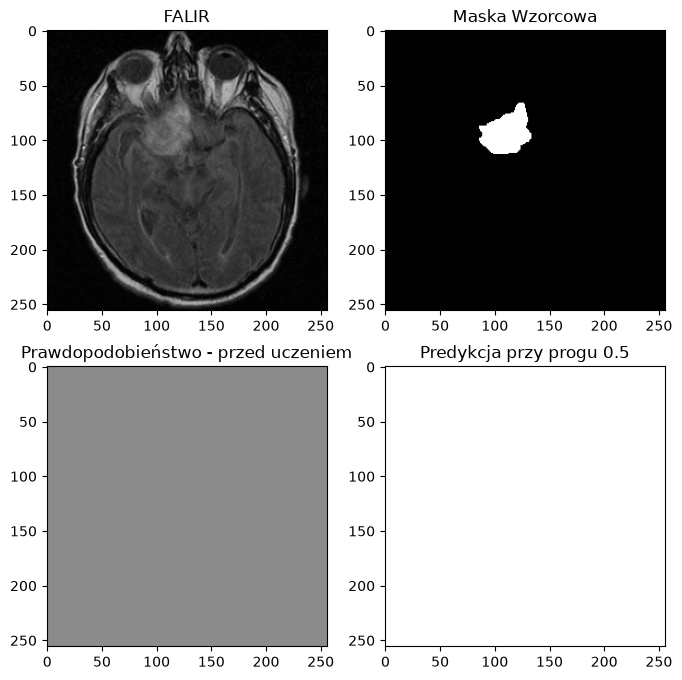

In [35]:
i = 0 
fig, ax = plt.subplots(2, 2, figsize=(8, 8))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FALIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - przed uczeniem")

ax[1, 1].imshow(real_predictions[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Predykcja przy progu 0.5")

plt.show()

In [36]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

real_model = real_model.to(device)
training_images = real_images.to(device)
training_masks = real_masks.to(device)

real_optimizer = torch.optim.Adam(real_model.parameters(), lr=1e-3)

print(device)

cuda


In [37]:
real_model.train()

for step in range(100):
    real_optimizer.zero_grad(set_to_none=True)
    logits = real_model(training_images)
    loss = criterion(logits, training_masks)
    loss.backward()
    real_optimizer.step()

    if (step + 1) % 20 == 0:
        print(step + 1, loss.item())

20 0.6892102956771851
40 0.13644389808177948
60 0.11477643996477127
80 0.09195548295974731
100 0.06114751845598221


In [38]:
real_model.eval()

with torch.no_grad():
    real_logits = real_model(training_images)
    real_probabilities = torch.sigmoid(real_logits).cpu()
    real_predictions = real_probabilities >= 0.5

In [39]:
print("Wzorzec:", real_masks.sum(dim=(1, 2, 3)))
print("Predykcja:", real_predictions.sum(dim=(1, 2, 3)))

intersection = real_predictions & (real_masks > 0)
print("Część wspólna:", intersection.sum(dim=(1, 2, 3)))

Wzorzec: tensor([1426., 2646.,    0.,    0.])
Predykcja: tensor([0, 0, 0, 0])
Część wspólna: tensor([0, 0, 0, 0])


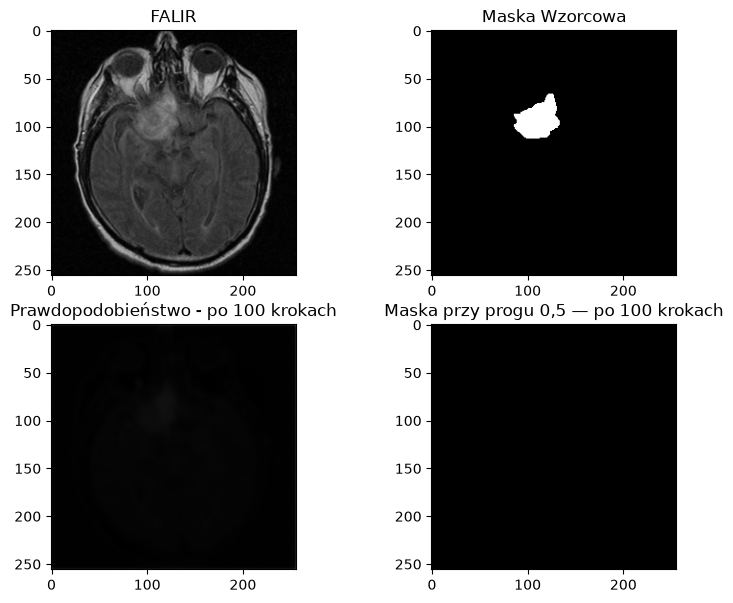

In [40]:
i = 0 
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FALIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - po 100 krokach")

ax[1, 1].imshow(real_predictions[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Maska przy progu 0,5 — po 100 krokach")

plt.show()

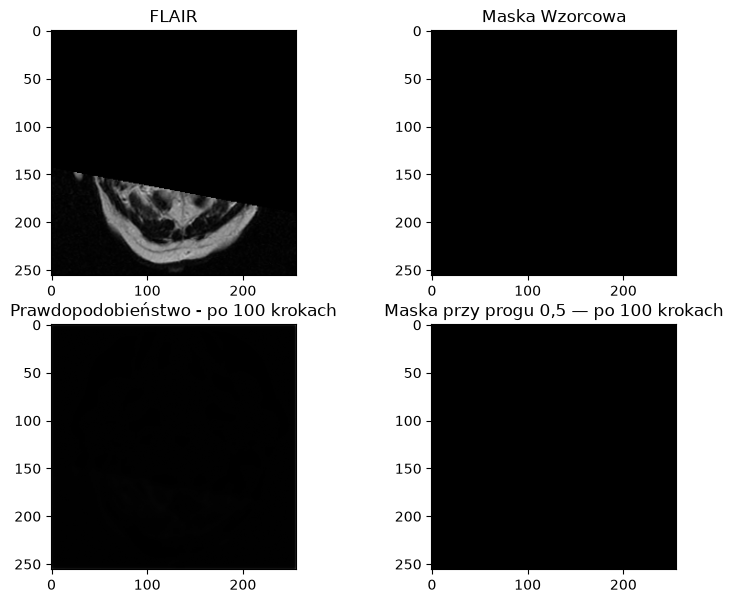

In [41]:
i = 2 
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FLAIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - po 100 krokach")

ax[1, 1].imshow(real_predictions[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Maska przy progu 0,5 — po 100 krokach")

plt.show()

In [42]:
foreground = real_masks > 0

print("Maksimum w całej paczce:",
      real_probabilities.max().item())

print("Średnia w oznaczeniu:",
      real_probabilities[foreground].mean().item())

print("Średnia poza oznaczeniem:",
      real_probabilities[~foreground].mean().item())

print("Maksimum w oznaczeniu:",
      real_probabilities[foreground].max().item())

Maksimum w całej paczce: 0.3350702226161957
Średnia w oznaczeniu: 0.05067134276032448
Średnia poza oznaczeniem: 0.012852920219302177
Maksimum w oznaczeniu: 0.07443329691886902


### kolejna pętla tylko większa

In [43]:
real_model.train()

for step in range(400):
    real_optimizer.zero_grad(set_to_none=True)
    logits = real_model(training_images)
    loss = criterion(logits, training_masks)
    loss.backward()
    real_optimizer.step()

    if (step + 1) % 20 == 0:
        print(step + 1, loss.item())

20 0.03251329064369202
40 0.022796280682086945
60 0.019547782838344574
80 0.017637066543102264
100 0.015109947882592678
120 0.01282878965139389
140 0.0076625412330031395
160 0.0067418040707707405
180 0.006508102174848318
200 0.006291558500379324
220 0.0060915215872228146
240 0.0058594862930476665
260 0.005589372478425503
280 0.005283216945827007
300 0.004961362574249506
320 0.004648636095225811
340 0.004372549708932638
360 0.0041623241268098354
380 0.003948376979678869
400 0.0037640349473804235


In [44]:
real_model.eval()

with torch.no_grad():
    real_logits = real_model(training_images)
    real_probabilities = torch.sigmoid(real_logits).cpu()
    real_predictions = real_probabilities >= 0.5

In [45]:
print("Wzorzec:", real_masks.sum(dim=(1, 2, 3)))
print("Predykcja:", real_predictions.sum(dim=(1, 2, 3)))

intersection = real_predictions & (real_masks > 0)
print("Część wspólna:", intersection.sum(dim=(1, 2, 3)))

Wzorzec: tensor([1426., 2646.,    0.,    0.])
Predykcja: tensor([1377, 2647,    0,    0])
Część wspólna: tensor([1326, 2532,    0,    0])


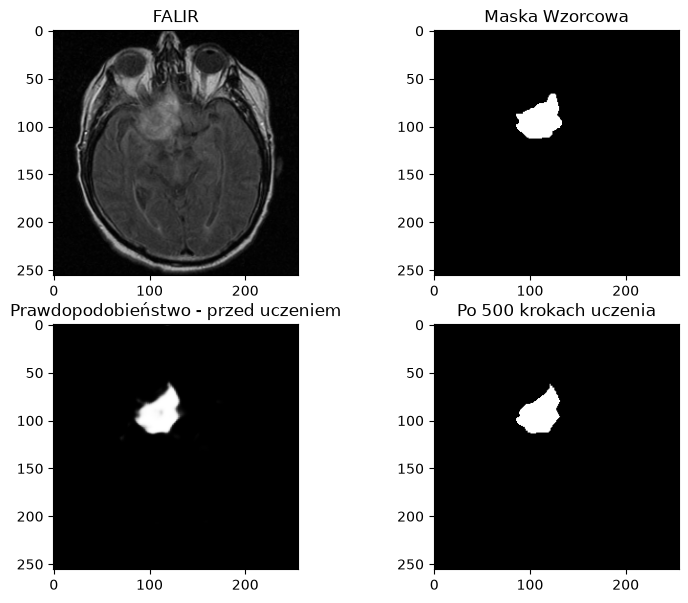

In [46]:
i = 0 
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FALIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - przed uczeniem")

ax[1, 1].imshow(real_predictions[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Po 500 krokach uczenia")

plt.show()

In [93]:
def dice_per_sample(predictions, targets):
    targets_logic = targets > 0

    targets_sum = targets_logic.sum(dim=(1, 2, 3))
    predictions_sum = predictions.sum(dim=(1, 2, 3))
    intersection = (targets_logic & predictions).sum(dim=(1, 2, 3))

    denominator = targets_sum + predictions_sum

    return torch.where(
        denominator == 0,
        1.0,
        2 * intersection / denominator.clamp_min(1)
    )

In [94]:
has_annotation = real_masks.sum(dim=(1, 2, 3)) > 0

In [97]:
dice_scores = dice_per_sample(real_predictions, real_masks)
print(dice_scores)
print("Średnie:")
print(dice_scores.mean().item())
print(dice_scores[has_annotation].mean().item())
print(dice_scores[~has_annotation].mean().item())

tensor([0.9461, 0.9567, 1.0000, 1.0000])
Średnie:
0.9757161140441895
0.9514322280883789
1.0
